# Modelo BiGRU: Entrenamiento y Evaluación

In [6]:
import os
import random
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import optuna

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.eval.losses import QLIKELoss
from src.eval.scorer import VolatilityScorer
from src.models.bigru_wrapper import BiGRUModel
from src.trainer.walk_forward import WalkForwardTrainer
from src.utils import trainer_toolkit as tt
from src.utils import ts_toolkit as tst
from src.utils import test_toolkit as ts

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

OUT_PATH = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results" / "bigru"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

df_train = pd.read_parquet(OUT_PATH / "brent_train.parquet")
y_train = df_train["log_returns"].values.astype("float64")
rs_train = df_train["rs_daily"].values.astype("float64")

df_test = pd.read_parquet(OUT_PATH / "brent_test.parquet")
y_test = df_test["log_returns"].values.astype("float64")
rs_test = df_test["rs_daily"].values.astype("float64")

assert not np.isnan(y_train).any() and not np.isnan(rs_train).any()
assert not np.isnan(y_test).any() and not np.isnan(rs_test).any()

print("=" * 70)
print(f"Train: {len(y_train)} obs  ({df_train.index[0].date()} -> {df_train.index[-1].date()})")
print(f"Test:  {len(y_test)} obs  ({df_test.index[0].date()} -> {df_test.index[-1].date()})")
print("=" * 70)

Train: 2171 obs  (2014-01-03 -> 2022-11-03)
Test:  953 obs  (2022-11-07 -> 2026-08-21)


## Introducción

La Unidad Recurrente con Compuertas Bidireccional (*Bidirectional Gated Recurrent Unit*, BiGRU) extiende la arquitectura GRU procesando cada ventana temporal en dos direcciones: hacia adelante (de los rezagos más antiguos hacia el instante más reciente) y hacia atrás (desde el extremo más reciente de la ventana hacia los rezagos anteriores). Al combinar ambos recorridos, la red construye representaciones ocultas que integran el contexto de la secuencia completa en cada paso antes de proyectar la varianza condicional.

En el pronóstico de volatilidad del crudo Brent bajo el protocolo del *benchmark*, la BiGRU permite capturar relaciones no lineales entre los retornos históricos y la varianza futura sin imponer una forma paramétrica previa. El objetivo de esta sección es presentar, entrenar y evaluar un modelo BiGRU manteniendo las mismas condiciones de información, preprocesamiento y validación que en el resto de modelos del proyecto.

### Arquitectura

Las ecuaciones internas de las compuertas de actualización $\left(\mathbf{z}_t\right)$, compuerta de reinicio $\left(\mathbf{r}_t\right)$, estado candidato ($\tilde{\mathbf{h}}_t$) y actualización del estado oculto son iguales que en el GRU, aplicadas de forma independiente a cada dirección temporal (directa e inversa).

A diferencia del GRU unidireccional, para una secuencia de longitud $L$, la capa BiGRU produce estados ocultos en ambos sentidos y toma los estados finales de la última capa en cada dirección, $\mathbf{h}_t^{\rightarrow} \in \mathbb{R}^{H}$ y $\mathbf{h}_t^{\leftarrow} \in \mathbb{R}^{H}$ (donde $H$ es el tamaño oculto `hidden_size`), concatenándolos en un vector de dimensión $2H$:

$$
\mathbf{h}_t^{\text{bi}} =
\begin{bmatrix}
\mathbf{h}_t^{\rightarrow} \\
\mathbf{h}_t^{\leftarrow}
\end{bmatrix}
\in \mathbb{R}^{2H}.
$$

Ese vector concatenado pasa por una capa lineal con pesos $\mathbf{w} \in \mathbb{R}^{2H}$ y sesgo $b \in \mathbb{R}$ para obtener la salida escalar previa:

$$
y_t = \mathbf{w}^{\top}\mathbf{h}_t^{\text{bi}} + b,
$$

y luego por la activación *Softplus* para garantizar una varianza estrictamente positiva:

$$
\hat{\sigma}_t^2 = \text{Softplus}(y_t) + \varepsilon = \ln\left(1 + e^{y_t}\right) + \varepsilon,
$$

donde $\varepsilon$ es una pequeña constante numérica positiva (`1e-8`) y $\boldsymbol{\theta}$ agrupa los parámetros entrenables de la red.

La estandarización Z sobre los retornos logarítmicos diarios (ajustada exclusivamente sobre el 80 % inicial de cada fold de entrenamiento para evitar fuga de información), la definición de la ventana de entrada $\mathbf{Z}_t \in \mathbb{R}^{L \times 1}$, la estrategia one-step-ahead minimizando la pérdida QLIKE frente a la varianza de Rogers-Satchell $\left(RS_i\right)$ y el entrenamiento con retropropagación y optimizador Adam siguen el mismo esquema que en el GRU. En la implementación en `PyTorch`, en cambio, la red se define mediante `BiGRUNetwork` con `bidirectional=True`, concatena los estados finales de ambas direcciones (`h_n[-2]` y `h_n[-1]`) y proyecta un vector de dimensión $2H$ hacia la salida con `Softplus`.

## Entrenamiento

Para la selección de hiperparámetros del modelo BiGRU, se mantuvo el mismo protocolo experimental Walk-Forward y el mismo presupuesto computacional que en los modelos paramétricos y en la GRU. A diferencia del GARCH y el EGARCH, la búsqueda de Optuna exploró la arquitectura de la red neuronal y sus parámetros de regularización sobre exactamente el mismo espacio de búsqueda que la GRU.

Para adaptar la serie temporal al formato requerido por la red, se construyó una matriz de rezagos para cada ventana del esquema Walk-Forward. Siguiendo los principios de validación cruzada para series temporales, cada fila de esta matriz contenía una secuencia histórica de longitud `look_back`, la cual se utilizó como vector de entrada para predecir el paso inmediatamente posterior. Este enfoque garantizó la integridad temporal de los datos y evitó cualquier tipo de fuga de información futura durante el entrenamiento.

El espacio de búsqueda incluyó exactamente los mismos hiperparámetros que en la GRU: la longitud de la ventana de entrada (`look_back`), el número de neuronas en la capa oculta (`hidden_size`), la cantidad de capas recurrentes, la tasa de abandono (`dropout`) y la tasa de aprendizaje. Para mitigar el sobreajuste, se incorporó también la penalización $\ell_2$ (`weight_decay`). El entrenamiento se configuró con un máximo de 200 épocas y una paciencia de 20 para la parada temprana interna de la red. El desempeño se siguió evaluando mediante la pérdida QLIKE sobre los conjuntos de validación.

In [ ]:
def bigru_search_space(trial: optuna.Trial) -> dict:
    return {
        "look_back": trial.suggest_categorical("look_back", [7, 14, 21, 28]),
        "hidden_size": trial.suggest_categorical("hidden_size", [32, 64, 128]),
        "num_layers": trial.suggest_int("num_layers", 1, 2),
        "dropout": trial.suggest_float("dropout", 0.0, 0.3),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "max_epochs": 200,
        "patience": 20,
        "retrain_freq": 1,
        "seed": 42,
    }


exec_id = 1
current_warmup = 1200 + (exec_id * 10)

exec_dir = RESULTS_PATH / f"exec_{exec_id}"
exec_dir.mkdir(parents=True, exist_ok=True)

trainer = WalkForwardTrainer(
    model_class=BiGRUModel,
    scorer=VolatilityScorer(),
    output_dir=exec_dir,
    n_splits=5,
    warmup=current_warmup,
    embargo=1,
    n_trials=50,
    suggest_params_fn=bigru_search_space,
    early_stop_rounds=15,
)

trainer.run(y_train, rs_train)

El algoritmo de búsqueda completó 47 ensayos de 50 posibles (94 %) y registró 2 ensayos podados, alcanzando un mejor valor de QLIKE de 0.4272. La poda puntual de 2 ensayos refleja que, pese a la mayor capacidad representacional derivada de concatenar ambos sentidos temporales, la mayoría de las configuraciones mantuvieron una evolución competitiva durante las primeras épocas sin requerir descartes tempranos masivos.

La búsqueda completa en Optuna tomó alrededor de 15 horas y media, mientras que el ajuste y reentrenamiento del modelo bajo el esquema *Walk-Forward* totalizó aproximadamente 8.98 minutos (538.76 segundos), con un promedio de 2.2080 segundos por partición. Este tiempo de ejecución refleja la carga computacional de procesar secuencias en doble sentido con Adam y retropropagación frente a arquitecturas más ligeras, conservando al mismo tiempo la viabilidad práctica dentro del protocolo *Walk-Forward*.

In [7]:
resumen_data = []

exec_id = 1
exec_dir = RESULTS_PATH / f"exec_{exec_id}"

tiempo_total_rep = 0.0
tiempo_promedio_fold = 0.0
num_folds = 0
total_trials, completos, podados, fallidos = 0, 0, 0, 0
mejor_qlike = "-"

csv_files = list(exec_dir.glob("*_results.csv"))
if csv_files:
    df_csv = pd.read_csv(csv_files[0])
    tiempo_total_rep = df_csv["train_time_sec"].sum()
    tiempo_promedio_fold = df_csv["train_time_sec"].mean()
    num_folds = len(df_csv)
else:
    print(f"No se encontró el CSV en {exec_dir}")

db_path = exec_dir / "optuna_study.db"
if db_path.exists():
    try:
        storage_url = f"sqlite:///{db_path.resolve()}"
        study = optuna.load_study(study_name="BiGRUModel_study", storage=storage_url)

        total_trials = len(study.trials)
        completos = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
        podados  = len([t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED])
        fallidos = len([t for t in study.trials if t.state == optuna.trial.TrialState.FAIL])

        mejor_qlike = round(study.best_value, 4)

    except Exception as e:
        print(f"Error leyendo BD en {exec_dir}: {e}")
else:
    print(f"No se encontró la BD en {db_path}")

resumen_data.append({
    "Total Trials": total_trials,
    "Completos": completos,
    "Podados": podados,
    "Mejor QLIKE": mejor_qlike,
    "Tiempo Total (s)": round(tiempo_total_rep, 2),
    "Tiempo por Fold (s)": round(tiempo_promedio_fold, 3)
})

df_search_params = pd.DataFrame(resumen_data)
tt.display_styled_df(df=df_search_params, decimals=4, align_left_first=False)

Total Trials,Completos,Podados,Mejor QLIKE,Tiempo Total (s),Tiempo por Fold (s)
50,47,2,0.4272,538.7600,2.2080


El ranking de configuraciones de la BiGRU mostró que las cinco mejores opciones presentaron una pérdida QLIKE media en el rango de 0.427 a 0.446. Las diferencias entre estos resultados fueron menores que la dispersión entre *folds* ($\sigma$ entre 0.095 y 0.121), lo que indicó un desempeño predictivo similar entre particiones dentro de este grupo. En estas configuraciones, el *lookback* fue de 21 días en tres casos, 14 días en uno y 7 días en otro, mientras que el número de neuronas fue de 64 en cuatro opciones y de 32 en la segunda, manteniendo en su mayoría una sola capa recurrente.

En comparación con la búsqueda realizada para la GRU, cuya configuración seleccionada empleó `look_back=7`, `hidden_size=128`, `num_layers=1`, `dropout=0.299`, `learning_rate=0.0065` y `weight_decay=6.5e-4`, las mejores configuraciones de la BiGRU tendieron a usar ventanas más largas (21 días en la mayoría de los casos) y un menor número de neuronas (`hidden_size=64` o `32`).

In [8]:
exec_dir = RESULTS_PATH / "exec_1"

df_bigru = pd.read_csv(exec_dir / "BiGRUModel_results.csv")

df_bigru["lr"] = df_bigru["learning_rate"].apply(lambda x: f"{x:.4f}")
df_bigru["wd"] = df_bigru["weight_decay"].apply(lambda x: f"{x:.1e}")

cols_agrupar = ["look_back", "hidden_size", "num_layers", "dropout", "lr", "wd"]
df_agg = df_bigru.groupby(cols_agrupar)["qlike"].agg(["mean", "std"]).reset_index()
df_agg["QLIKE"] = df_agg.apply(lambda x: f"{x['mean']:.3f} ± {x['std']:.3f}", axis=1)
df_top5 = df_agg.sort_values(by="mean").head(5)

df_top5 = df_top5.rename(columns={
    "look_back": "Lookback",
    "hidden_size": "Neuronas",
    "num_layers": "Capas",
    "dropout": "Dropout",
    "lr": "LR",
    "wd": "Weight Decay"
})

df_final = df_top5[["Lookback", "Neuronas", "Capas", "Dropout", "LR", "Weight Decay", "QLIKE"]]

tt.display_styled_df(df=df_final, align_left_first=False, decimals=3)

Lookback,Neuronas,Capas,Dropout,LR,Weight Decay,QLIKE
21,64,1,0.216,0.0003,6.1e-04,0.427 ± 0.095
14,32,2,0.295,0.0001,4.5e-04,0.428 ± 0.116
21,64,1,0.270,0.0001,5.3e-04,0.441 ± 0.121
21,64,1,0.197,0.0001,1.1e-04,0.444 ± 0.116
7,64,1,0.229,0.0002,3.9e-04,0.446 ± 0.100


Entre las opciones de la tabla, la primera configuración se eligió como la mejor no solo por registrar el menor QLIKE medio (0.427 ± 0.095) y la menor dispersión entre *folds* frente a la segunda opción (0.428 ± 0.116), sino también por emplear menos capas ocultas, lo que reduce el riesgo de sobreajuste y promueve la parsimonia del modelo. Asimismo, se diferencia de la segunda opción por utilizar `look_back=21` frente a 14, `hidden_size=64` frente a 32, una tasa de aprendizaje ligeramente mayor (`0.0003` frente a `0.0001`) y un *dropout* menor (`0.216` frente a `0.295`).

In [8]:
import time

scorer = VolatilityScorer()

best_model = BiGRUModel(
    look_back=14,
    hidden_size=64,
    num_layers=1,
    dropout=0.2,
    learning_rate=1e-3,
    weight_decay=1e-6,
    max_epochs=200,
    patience=20,
    batch_size=128,
    retrain_freq=1,
    seed=42,
)

start_time = time.time()
best_model.fit(y_train, rs_train)
end_time = time.time()

elapsed_time = end_time - start_time
print(f">> fit OK en {elapsed_time:.2f} s")
print("   diagnostics:", best_model.get_diagnostics())

>> fit OK en 21.53 s
   diagnostics: {'converged': True, 'epochs_run': 23}


In [7]:
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
from src.utils import test_toolkit as ts

best_model.net.eval()
look_back = best_model.context_length

# Escalar y_train igual que en fit() y armar ventanas de longitud look_back
y_train_scaled = best_model.scaler.transform(y_train.reshape(-1, 1)).flatten()
rs_train_scaled_target = rs_train * best_model.target_scale

x_windows = np.lib.stride_tricks.sliding_window_view(y_train_scaled, window_shape=look_back)
x_windows = x_windows[:-1, :, None].astype(np.float32)  # (N - look_back, look_back, 1)
y_targets = rs_train_scaled_target[look_back:].astype(np.float32)

train_eval_dataset = TensorDataset(
    torch.tensor(x_windows, dtype=torch.float32),
    torch.tensor(y_targets, dtype=torch.float32),
)
train_eval_loader = DataLoader(
    train_eval_dataset, batch_size=best_model.batch_size, shuffle=False
)

preds_train_list = []
with torch.no_grad():
    for x_batch, _ in train_eval_loader:
        x_batch = x_batch.to(best_model.device)
        preds_batch = best_model.net(x_batch).squeeze(-1).cpu().numpy()
        preds_train_list.append(preds_batch)

# Revertir target_scale para quedar en varianza original
preds_train_var = np.concatenate(preds_train_list) / best_model.target_scale
n_preds = len(preds_train_var)

dates_aligned = df_train.index[look_back : look_back + n_preds]
rs_volatilidad_aligned = np.sqrt(
    np.maximum(rs_train[look_back : look_back + n_preds], 0.0)
)
pred_volatilidad = np.sqrt(np.maximum(preds_train_var, 0.0))

mask_crisis = (dates_aligned >= "2020-01-01") & (dates_aligned <= "2020-06-30")

ts.plot_volatility_fit(
    dates=dates_aligned,
    rs_variance=rs_volatilidad_aligned,
    pred_variance=pred_volatilidad,
    title="Ajuste dentro de la Muestra de Entrenamiento (BiGRU)",
    ylab="Volatilidad",
    label_realized=r"Volatilidad Realizada $\left(\sigma_R\right)$",
    label_pred=r"Volatilidad BiGRU $\left(\hat{\sigma}_t\right)$",
    ylim=(-0.01, 0.35),
    legend_bbox=(0.01, 0.98),
    zoom_slice=mask_crisis,
    zoom_pad_frac=0.04,
    zoom_title="Zoom: Crisis COVID-19",
    zoom_bbox=(0.18, 0.35, 0.40, 0.40),
    title_size=14,
    label_size=14,
    tick_size=12,
    legend_size=14,
)

NameError: name 'best_model' is not defined

In [3]:
import time
import numpy as np

T, L = 3000, 21
rng = np.random.default_rng(0)

# log-varianza AR(1): la persistencia es la única señal
z = np.zeros(T)
for t in range(1, T):
    z[t] = 0.95 * z[t - 1] + 0.3 * rng.standard_normal()

rv_input = (np.exp(z) - np.exp(z).mean()) / np.exp(z).std()
y_target = np.exp(z).astype(np.float64)

syn_model = BiGRUModel(
    look_back=L,
    hidden_size=64,
    num_layers=1,
    dropout=0.2,
    learning_rate=1e-3,
    weight_decay=1e-6,
    max_epochs=200,
    patience=20,
    batch_size=128,
    retrain_freq=1,
    fine_tune_epochs=1,
    seed=42,
)

start_time = time.time()
syn_model.fit(rv_input, y_target)
elapsed_time = time.time() - start_time

print(f">> fit OK en {elapsed_time:.2f} s")
print("   diagnostics:", syn_model.get_diagnostics())

>> fit OK en 305.82 s
   diagnostics: {'converged': True, 'epochs_run': 194}


n_preds: 2979 | corr(pred, y_target): 0.9250
pred   min/mean/max/std: 0.1121 / 1.2739 / 12.8189 / 1.3422
target min/mean/max/std: 0.0535 / 1.2834 / 21.8828 / 1.5117
ratio std (pred / target): 0.8879


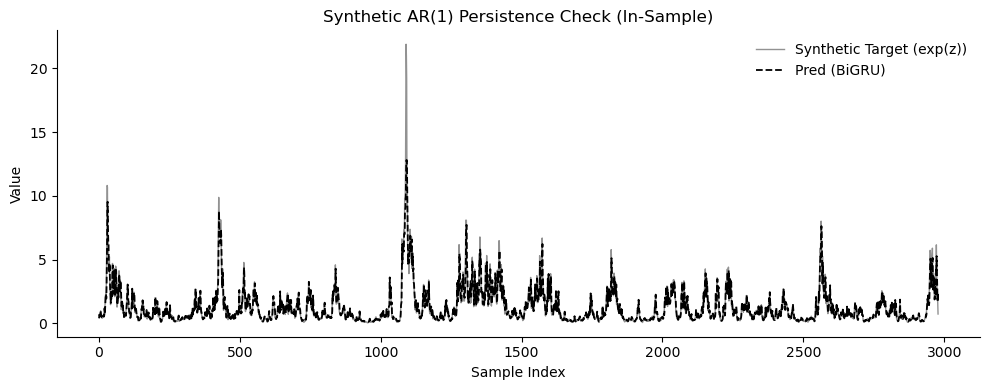

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

# Cambia syn_model por syn_fast si corriste ese
mdl = syn_model
mdl.net.eval()
lb = mdl.context_length

rv_scaled = mdl.scaler.transform(rv_input.reshape(-1, 1)).flatten().astype(np.float32)
y_scaled_target = (y_target * mdl.target_scale).astype(np.float32)

# Ventanas deslizantes de longitud lb: X tiene forma (N, lb, 1)
X_win = np.lib.stride_tricks.sliding_window_view(rv_scaled, lb)[:-1, :, None]
y_win = y_scaled_target[lb:]

ds_syn = TensorDataset(torch.from_numpy(X_win), torch.from_numpy(y_win))
loader_syn = DataLoader(ds_syn, batch_size=len(ds_syn), shuffle=False)

with torch.no_grad():
    for x_b, _ in loader_syn:
        pred_syn = (
            mdl.net(x_b.to(mdl.device)).squeeze(-1).cpu().numpy() / mdl.target_scale
        )

y_aligned = y_target[lb : lb + len(pred_syn)]
corr = np.corrcoef(pred_syn, y_aligned)[0, 1]

print(f"n_preds: {len(pred_syn)} | corr(pred, y_target): {corr:.4f}")
print(
    f"pred   min/mean/max/std: {pred_syn.min():.4f} / {pred_syn.mean():.4f} / "
    f"{pred_syn.max():.4f} / {pred_syn.std():.4f}"
)
print(
    f"target min/mean/max/std: {y_aligned.min():.4f} / {y_aligned.mean():.4f} / "
    f"{y_aligned.max():.4f} / {y_aligned.std():.4f}"
)
print(f"ratio std (pred / target): {pred_syn.std() / y_aligned.std():.4f}")

x_idx = np.arange(len(pred_syn))
plt.figure(figsize=(10, 4))
plt.plot(
    x_idx,
    y_aligned,
    color="#7f7f7f",
    linestyle="-",
    linewidth=1.0,
    alpha=0.85,
    label="Synthetic Target (exp(z))",
)
plt.plot(
    x_idx,
    pred_syn,
    color="#000000",
    linestyle="--",
    linewidth=1.3,
    label="Pred (BiGRU)",
)
plt.xlabel("Sample Index")
plt.ylabel("Value")
plt.title("Synthetic AR(1) Persistence Check (In-Sample)")
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

In [11]:
import numpy as np
import torch
import torch.nn as nn

L = 21
y_sc = best_model.scaler.transform(y_train.reshape(-1, 1)).flatten().astype(np.float32)
tgt_raw = (rs_train * best_model.target_scale).astype(np.float32)

X = np.lib.stride_tricks.sliding_window_view(y_sc, L)[:-1, :, None].astype(np.float32)
y_raw = tgt_raw[L:]

# 1. Revisar escala original del target
raw_mean = float(y_raw.mean())
print(f"y_raw mean/std/max: {raw_mean:.6e} / {y_raw.std():.6e} / {y_raw.max():.6e}")

# 2. Llevar el target a media ~1 (recordando dividir por target_factor al recuperar escala)
target_factor = 1.0 / max(raw_mean, 1e-12)
y = (y_raw * target_factor).astype(np.float32)
print(f"y_scaled_mean1 mean/std/max: {y.mean():.6f} / {y.std():.6f} / {y.max():.6f}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reutiliza la red de best_model y reinicia parámetros
net = best_model.net.to(device)
for m in net.modules():
    if hasattr(m, "reset_parameters"):
        m.reset_parameters()

# Inicialización de salida cercana a la media (asumiendo cabeza con Softplus y capa fc)
with torch.no_grad():
    m_val = max(float(y.mean()), 1e-6)
    inv_softplus = np.log(np.expm1(m_val)) if m_val < 20.0 else m_val
    if hasattr(net, "fc") and hasattr(net.fc, "bias") and net.fc.bias is not None:
        net.fc.bias.fill_(float(inv_softplus))
        if hasattr(net.fc, "weight") and net.fc.weight is not None:
            net.fc.weight.mul_(0.1)

opt = torch.optim.Adam(net.parameters(), lr=1e-3)
Xt = torch.tensor(X, device=device)
yt = torch.tensor(y, device=device)

epochs = 1000
for ep in range(epochs):
    net.train()
    p = net(Xt).squeeze(-1)
    loss = (yt / p - torch.log(yt / p) - 1).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()

    if ep % 100 == 0 or ep == epochs - 1:
        with torch.no_grad():
            # Predicción devuelta a la escala original de y_raw
            p_orig = p.detach().cpu().numpy() / target_factor
            y_orig = yt.detach().cpu().numpy() / target_factor
            corr = np.corrcoef(p_orig, y_orig)[0, 1] if p_orig.std() > 0 else np.nan
            print(
                f"ep={ep:04d} | loss={loss.item():.6f} | "
                f"p_std={p_orig.std():.6e} | p_max={p_orig.max():.6e} | corr={corr:.4f}"
            )

y_raw mean/std/max: 6.223947e-04 / 2.148921e-03 / 6.201491e-02
y_scaled_mean1 mean/std/max: 1.000000 / 3.452666 / 99.639198
ep=0000 | loss=0.802842 | p_std=5.626655e-07 | p_max=6.247571e-04 | corr=0.0248
ep=0100 | loss=0.468964 | p_std=5.295188e-04 | p_max=3.247655e-03 | corr=0.4334
ep=0200 | loss=0.367771 | p_std=5.994271e-04 | p_max=4.437020e-03 | corr=0.4915
ep=0300 | loss=0.350098 | p_std=6.502361e-04 | p_max=5.107176e-03 | corr=0.5245
ep=0400 | loss=0.332720 | p_std=7.390910e-04 | p_max=6.057738e-03 | corr=0.5519
ep=0500 | loss=0.314320 | p_std=8.168447e-04 | p_max=6.951556e-03 | corr=0.5779
ep=0600 | loss=0.301519 | p_std=8.474126e-04 | p_max=7.826853e-03 | corr=0.6061
ep=0700 | loss=0.293559 | p_std=8.773456e-04 | p_max=8.484264e-03 | corr=0.6204
ep=0800 | loss=0.285406 | p_std=9.394300e-04 | p_max=9.082095e-03 | corr=0.6241
ep=0900 | loss=0.276191 | p_std=9.605726e-04 | p_max=9.600434e-03 | corr=0.6330
ep=0999 | loss=0.267217 | p_std=9.925109e-04 | p_max=1.008258e-02 | corr=0.6